# Credit card default early warning

Jiahui Zhang | Independent banking analytics case study

At 10% review capacity, the delinquency rule found **414** defaults and logistic regression found **412**. The model's difference was **-2 defaults per 600 reviews**, with a 95% paired bootstrap interval of **-17 to +10**. This test supports keeping the rule as the benchmark at the specified capacity.

## Context and method

A collections team can manually review 10% of active card clients. Each approach ranks the same test clients using only information recorded before the target month. The outcome is the source's next-month default flag. A review is a queue slot and does not measure prevented defaults.

### Key assumptions

- One held-out cohort from the same historical snapshot. There is no later vintage in this data for an out-of-time test.
- The rule prioritises latest delay severity, then number of late months, then the largest delay. Equal scores use a fixed seeded order. The client identifier stays out of scoring.
- The model is fixed L2-regularised logistic regression. Its scaler and coefficients are fitted on training data only. Capacity is fixed before inspecting model performance.
- Sex, age, education and marital status are excluded from scoring. Recorded sex is used below for a descriptive subgroup check.

## Data

Yeh's UCI Default of Credit Card Clients dataset contains six months of history, April to September 2005, for 30,000 clients in Taiwan. The retained CSV came from the pinned scikit-learn mirror. The loader verifies its SHA-256 and checks unique IDs, row counts, missingness, labels and key ranges.

[UCI source and citation](https://doi.org/10.24432/C55S3H) · [Exact CSV mirror revision](https://huggingface.co/datasets/scikit-learn/credit-card-clients/blob/f809522/UCI_Credit_Card.csv)

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
from analysis import (
    TARGET, MODEL, RULE, load_data, build_features, run_experiment,
    paired_bootstrap, plot_capacity, queue_breakdown, ranking_metrics, subgroup_results,
)

raw = load_data()
print(f"{len(raw):,} clients | {raw[TARGET].sum():,} defaults | {raw[TARGET].mean():.2%} prevalence")
print(f"Duplicate client IDs: {raw.index.duplicated().sum()} | Missing values: {raw.isna().sum().sum()}")
display(raw.groupby("PAY_0")[TARGET].agg(Clients="size", Defaults="sum", Default_rate="mean")
        .rename_axis("Latest repayment status")
        .style.format({"Default_rate": "{:.1%}"}))

30,000 clients | 6,636 defaults | 22.12% prevalence
Duplicate client IDs: 0 | Missing values: 0


,Clients,Defaults,Default_rate
Latest repayment status,,,
-2,2759,365,13.2%
-1,5686,954,16.8%
0,14737,1888,12.8%
1,3688,1252,33.9%
2,2667,1844,69.1%
3,322,244,75.8%
4,76,52,68.4%
5,26,13,50.0%
6,11,6,54.5%


### Create features and split clients

Positive repayment codes count as delay months. The model preserves the common negative status codes separately without imposing undocumented meanings. Bill-to-limit ratios retain negative balances and are clipped to [-1, 3] to limit the influence of extreme ratios. Payment history, bill utilisation and the credit limit are measured as of the snapshot.

In [2]:
train, test, model, scores, orders, results = run_experiment(raw)
actual = test[TARGET].to_numpy()
capacity = int(results.loc[MODEL, "Reviewed"])
print(f"Train: {len(train):,} | Test: {len(test):,} | Test defaults: {actual.sum():,} | Review slots: {capacity}")
print("Model features:")
print(", ".join(build_features(raw).columns))

Train: 24,000 | Test: 6,000 | Test defaults: 1,327 | Review slots: 600
Model features:
Recent status -2, Recent status -1, Recent delay 1 month, Recent delay 2 months, Recent delay 3+ months, Older late months, Older maximum delay, Recent bill to limit, Mean bill to limit, Log credit limit, Log mean payment, Months with zero payment


## Results

Precision is the share of reviewed clients who defaulted. Recall is the share of all held-out defaults found by the queue.

In [3]:
display(results.style.format({"Precision": "{:.1%}", "Recall": "{:.1%}"}))
low, high = paired_bootstrap(actual, orders, capacity)
print(f"Model minus rule: {results.loc[MODEL, 'Defaults found'] - results.loc[RULE, 'Defaults found']:+.0f} defaults")
print(f"95% paired percentile bootstrap interval: {low:+.0f} to {high:+.0f} defaults per {capacity} reviews")
display(queue_breakdown(test, orders, capacity))

,Reviewed,Defaults found,Defaults missed,Non-defaults reviewed,Precision,Recall
Delinquency rule,600,414,913,186,69.0%,31.2%
Logistic regression,600,412,915,188,68.7%,31.0%


Model minus rule: -2 defaults
95% paired percentile bootstrap interval: -17 to +10 defaults per 600 reviews


,Reviewed,Defaults found
Both,536,377
Logistic only,64,35
Rule only,64,37


The paired bootstrap reranks both queues over the same 1,500 resamples of the held-out clients. This interval describes test-cohort sampling variation conditional on the fitted model and tie-break. It leaves retraining and changes across vintages unmeasured.

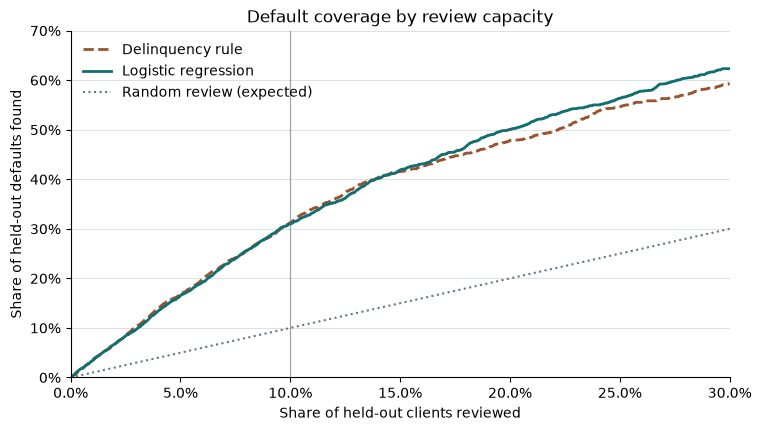

In [4]:
fig = plot_capacity(actual, orders)
display(fig)
plt.close(fig)

### Check overall ranking and subgroup coverage

ROC AUC and average precision summarise ordering across thresholds. Brier score measures squared probability error and is reported for the probability model and a constant training-prevalence forecast. Subgroup denominators appear with the results so rates remain interpretable.

In [5]:
display(ranking_metrics(train, test, scores).style.format("{:.3f}", na_rep="N/A"))
display(subgroup_results(test, orders, capacity).style.format({"Recall": "{:.1%}", "Precision": "{:.1%}"}))

,ROC AUC,Average precision,Brier score,Constant-probability Brier
Delinquency rule,0.722,0.481,N/A,N/A
Logistic regression,0.766,0.532,0.138,0.172


## Takeaways

The model improves overall ROC AUC and average precision, while the fixed-budget queues cover nearly the same number of defaults. The overlap table shows how few accounts changed at the cutoff. The observed subgroup differences are descriptive and do not establish fairness.

Keep the delinquency rule as the benchmark at 10% capacity. A future evaluation would use a later vintage from the target lender, check calibration and subgroup performance, and measure what the team can achieve after review. This Taiwan 2005 snapshot provides a retrospective comparison for a portfolio project.